# CSCI 3151 — Foundations of Machine Learning  
## M45 — Modern CNNs: ResNets and Beyond

**Team 26**

**Savina Palihakkara - B01017193**

**Yanrui Wang - B01021602**

**Weili Wang - B00960200**

In this mini-lab, you'll work with **small convolutional networks** on a subset of CIFAR-10 images (tiny 32×32 colour photos from 10 classes). We'll compare a **plain CNN** to a **ResNet-style CNN with skip connections**, focusing on:

- How depth affects **trainability** (the *degradation problem*).
- How **residual connections** change optimization behaviour.
- What we can see in **training/validation curves** and simple statistics.

You can think of the data-generating process (DGP) as: a camera captures natural images, they are labelled into 10 object categories, and we train models to map pixels → labels. Stakeholders include ML engineers and teams deploying vision systems; risks include **overconfident mistakes** and **brittle behaviour** if we misinterpret our models' performance.

**This mini-lab reinforces…**

- The degradation problem in deep plain CNNs (deeper ≠ automatically better).
- Residual blocks and identity shortcuts as tools for stable optimization.
- Reading training/validation curves to reason about optimization vs capacity.
- Connecting ResNets back to gradient-flow and generalization ideas from earlier modules.

<!-- fileciteturn0file0turn0file1 -->


## Assumptions & scope

- You are comfortable with basic **Python**, **NumPy**, and **PyTorch**, including tensors, modules, and a simple training loop.
- You've already seen **basic CNNs** (convolutions, pooling) and **gradient-based training** in earlier modules.
- To keep runtime small, we:
  - Work on a **small subset** of CIFAR-10 (a few thousand images, not the full 50k).
  - Use **tiny networks** and only a **couple of epochs** per model.
  - Focus on **qualitative comparisons** (which model trains more easily?) rather than best possible accuracy.
- We **do not** try to reproduce large-scale ResNet results or advanced tricks from the paper; those are intentionally out of scope for this ~30-minute mini-lab.


In [1]:
# Setup: imports and configuration

import random
import time
from dataclasses import dataclass

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

# Make plots appear inline and use a slightly nicer default style
plt.style.use("default")

# Reproducibility
SEED = 3151
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED) if torch.cuda.is_available() else None

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DEVICE


device(type='cpu')

In [2]:
# Data: small CIFAR-10 subset

transform = transforms.Compose([
    transforms.ToTensor(),
    # Normalize roughly to zero mean / unit variance per channel
    transforms.Normalize((0.4914, 0.4822, 0.4465),
                         (0.2470, 0.2435, 0.2616)),
])

train_full = datasets.CIFAR10(root="data", train=True, download=True, transform=transform)
test_full  = datasets.CIFAR10(root="data", train=False, download=True, transform=transform)

# Use a relatively small subset to keep training quick (≤ 5k examples total).
train_indices = np.arange(0, 4000)   # 4k training examples
val_indices   = np.arange(4000, 5000)  # 1k for validation (still from train split)

train_ds = Subset(train_full, train_indices)
val_ds   = Subset(train_full, val_indices)

BATCH_SIZE = 64

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=2, pin_memory=True)
val_loader   = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)

len(train_ds), len(val_ds)


(4000, 1000)

## Core Task 1 — Plain CNN vs. ResNet-style CNN (architecture)

We'll define two small models:

- `PlainCNN`: a stack of convolutional blocks without skip connections.
- `ResNetSmall`: uses **residual blocks** with identity shortcuts where shapes match.

Your job in this section:

1. Read the code and make sure you understand where the **skip connection** is.
2. Trace through one `BasicBlock` on paper or in your head: what shapes do you expect after each line?
3. Run the sanity-check cell to compare parameter counts and output shapes.


In [3]:
# Model definitions: small plain CNN + small ResNet-style CNN

class ConvBlock(nn.Module):
    """Conv → BatchNorm → ReLU with optional stride > 1 for downsampling."""
    def __init__(self, in_channels, out_channels, kernel_size=3, stride=1):
        super().__init__()
        padding = kernel_size // 2
        self.conv = nn.Conv2d(in_channels, out_channels, kernel_size,
                              stride=stride, padding=padding, bias=False)
        self.bn = nn.BatchNorm2d(out_channels)
        self.relu = nn.ReLU(inplace=True)

    def forward(self, x):
        x = self.conv(x)
        x = self.bn(x)
        x = self.relu(x)
        return x


class PlainCNN(nn.Module):
    """A tiny plain CNN with no residual connections."""
    def __init__(self, num_classes=10):
        super().__init__()
        self.features = nn.Sequential(
            ConvBlock(3, 32, stride=1),
            ConvBlock(32, 64, stride=2),   # downsample
            ConvBlock(64, 128, stride=2),  # downsample
            ConvBlock(128, 128, stride=1),
        )
        self.pool = nn.AdaptiveAvgPool2d((1, 1))
        self.fc = nn.Linear(128, num_classes)

    def forward(self, x):
        x = self.features(x)
        x = self.pool(x)
        x = torch.flatten(x, 1)
        x = self.fc(x)
        return x


class BasicBlock(nn.Module):
    """A simplified residual block (like a small ResNet block)."""
    expansion = 1

    def __init__(self, in_channels, out_channels, stride=1):
        super().__init__()
        self.conv1 = ConvBlock(in_channels, out_channels, stride=stride)
        # Second conv *without* ReLU at the end; we'll add it after the residual sum.
        self.conv2_conv = nn.Conv2d(out_channels, out_channels, kernel_size=3,
                                    stride=1, padding=1, bias=False)
        self.conv2_bn = nn.BatchNorm2d(out_channels)

        # If input and output shapes differ (channels or stride), use a 1x1 conv projection.
        if stride != 1 or in_channels != out_channels:
            self.downsample = nn.Sequential(
                nn.Conv2d(in_channels, out_channels, kernel_size=1,
                          stride=stride, bias=False),
                nn.BatchNorm2d(out_channels),
            )
        else:
            self.downsample = None

        self.relu = nn.ReLU(inplace=True)

    def forward(self, x):
        identity = x

        out = self.conv1(x)
        out = self.conv2_conv(out)
        out = self.conv2_bn(out)

        # Residual / skip connection:
        # - if downsample is defined, project the identity to match shape
        # - otherwise, use the raw input as the identity mapping
        if self.downsample is not None:
            residual = self.downsample(identity)
        else:
            residual = identity

        out = out + residual
        out = self.relu(out)
        return out


class ResNetSmall(nn.Module):
    """A very small ResNet-ish model for CIFAR-10 sized images."""
    def __init__(self, num_classes=10):
        super().__init__()
        self.stem = ConvBlock(3, 32, stride=1)

        # Two stages with residual blocks; one downsampling between them.
        self.layer1 = nn.Sequential(
            BasicBlock(32, 32, stride=1),
            BasicBlock(32, 32, stride=1),
        )
        self.layer2 = nn.Sequential(
            BasicBlock(32, 64, stride=2),  # downsample + increase channels
            BasicBlock(64, 64, stride=1),
        )
        self.layer3 = nn.Sequential(
            BasicBlock(64, 128, stride=2),
            BasicBlock(128, 128, stride=1),
        )

        self.pool = nn.AdaptiveAvgPool2d((1, 1))
        self.fc = nn.Linear(128, num_classes)

    def forward(self, x):
        x = self.stem(x)
        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        x = self.pool(x)
        x = torch.flatten(x, 1)
        x = self.fc(x)
        return x


def count_parameters(model: nn.Module) -> int:
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


plain = PlainCNN().to(DEVICE)
resnet = ResNetSmall().to(DEVICE)

print(plain)
print(f"PlainCNN parameters: {count_parameters(plain):,}")
print()
print(resnet)
print(f"ResNetSmall parameters: {count_parameters(resnet):,}")


PlainCNN(
  (features): Sequential(
    (0): ConvBlock(
      (conv): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
    )
    (1): ConvBlock(
      (conv): Conv2d(32, 64, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (bn): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
    )
    (2): ConvBlock(
      (conv): Conv2d(64, 128, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (bn): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
    )
    (3): ConvBlock(
      (conv): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_run

📝 **Quick reflection**

In a short markdown cell of your own (below this one), answer:

1. Where in `BasicBlock` does the **identity mapping** enter the computation?
  - Line 55-58. Applying `Conv2d` and `conv2_bn` to the input.
2. Why do we sometimes need the 1×1 convolution **projection shortcut** (i.e., when `stride != 1` or `in_channels != out_channels`)? Relate this to tensor shapes.
  - Because the size of `in_channels` is not equal to `out_channels`. If the block is skipped, returning the input directly does not match the output dimension. Therefore, input needs to be transformed to the dimension of the output.
  - `stride != 1` also makes dimension mismatch.


## Core Task 2 — Training curves: degradation vs. residual connections

Now we'll train both models for a small number of epochs and compare:

- training loss
- validation loss
- validation accuracy

We'll use the **same optimizer and hyperparameters** so that the main difference is the presence/absence of residual connections.


In [4]:
@dataclass
class TrainHistory:
    train_loss: list
    val_loss: list
    val_acc: list


def accuracy_from_logits(logits, targets):
    preds = logits.argmax(dim=1)
    return (preds == targets).float().mean().item()


def train_one_epoch(model, loader, optimizer, criterion):
    model.train()
    running_loss = 0.0
    for inputs, targets in loader:
        inputs = inputs.to(DEVICE, non_blocking=True)
        targets = targets.to(DEVICE, non_blocking=True)

        # Standard training steps:
        # 1. Zero out gradients
        # 2. Forward pass to get logits
        # 3. Compute loss
        # 4. Backward pass
        # 5. Optimizer step
        optimizer.zero_grad()
        logits = model(inputs)
        loss = criterion(logits, targets)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * inputs.size(0)

    return running_loss / len(loader.dataset)


@torch.no_grad()
def evaluate(model, loader, criterion):
    model.eval()
    running_loss = 0.0
    running_acc = 0.0
    n_examples = 0

    for inputs, targets in loader:
        inputs = inputs.to(DEVICE, non_blocking=True)
        targets = targets.to(DEVICE, non_blocking=True)

        logits = model(inputs)
        loss = criterion(logits, targets)

        batch_size = inputs.size(0)
        running_loss += loss.item() * batch_size
        running_acc += accuracy_from_logits(logits, targets) * batch_size
        n_examples += batch_size

    return running_loss / n_examples, running_acc / n_examples


def train_model(model, train_loader, val_loader, epochs=3, lr=1e-3, weight_decay=0.0):
    model = model.to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    criterion = nn.CrossEntropyLoss()

    hist = TrainHistory(train_loss=[], val_loss=[], val_acc=[])

    for epoch in range(1, epochs + 1):
        t0 = time.time()
        train_loss = train_one_epoch(model, train_loader, optimizer, criterion)
        val_loss, val_acc = evaluate(model, val_loader, criterion)
        dt = time.time() - t0

        hist.train_loss.append(train_loss)
        hist.val_loss.append(val_loss)
        hist.val_acc.append(val_acc)

        print(f"Epoch {epoch:02d} | train loss {train_loss:.3f} | "
              f"val loss {val_loss:.3f} | val acc {val_acc:.3f} | {dt:.1f}s")

        
    return hist


In [5]:
# Train both models for a few epochs

EPOCHS = 3  # keep this small for class; feel free to increase later if you have time/compute
LR = 1e-3
WEIGHT_DECAY = 5e-4  # a bit of L2 regularization

plain = PlainCNN().to(DEVICE)
resnet = ResNetSmall().to(DEVICE)

print("Training PlainCNN")
hist_plain = train_model(plain, train_loader, val_loader, epochs=EPOCHS, lr=LR, weight_decay=WEIGHT_DECAY)

print("\nTraining ResNetSmall")
hist_resnet = train_model(resnet, train_loader, val_loader, epochs=EPOCHS, lr=LR, weight_decay=WEIGHT_DECAY)


Training PlainCNN


/Users/yanrui/Developer/CSCourses/csci3151/.venv/lib/python3.15/site-packages/torch/utils/data/dataloader.py:1102: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


Epoch 01 | train loss 1.877 | val loss 1.867 | val acc 0.327 | 26.8s
Epoch 02 | train loss 1.619 | val loss 1.602 | val acc 0.432 | 26.7s
Epoch 03 | train loss 1.454 | val loss 1.468 | val acc 0.475 | 26.7s

Training ResNetSmall
Epoch 01 | train loss 1.799 | val loss 1.813 | val acc 0.372 | 38.0s
Epoch 02 | train loss 1.508 | val loss 1.965 | val acc 0.371 | 37.9s
Epoch 03 | train loss 1.346 | val loss 1.712 | val acc 0.393 | 37.6s


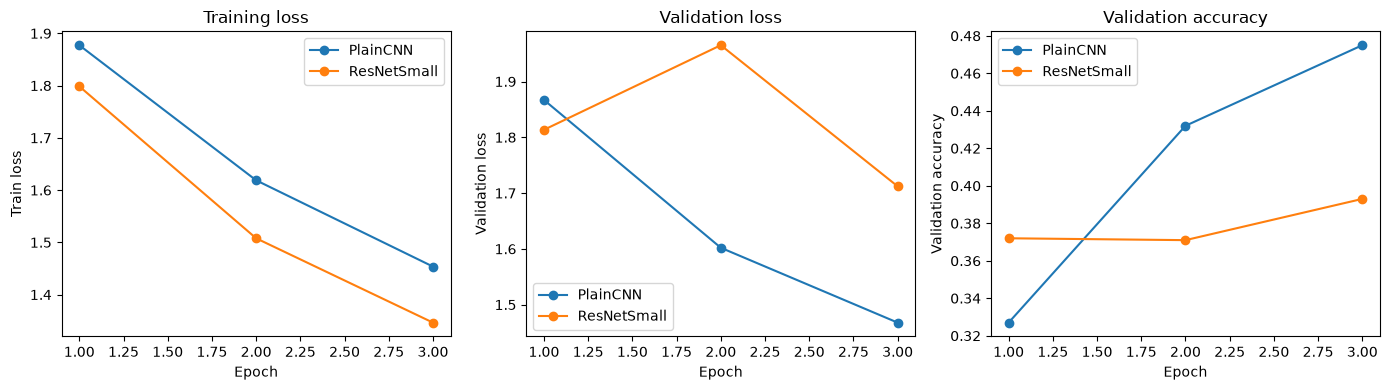

In [6]:
# Plot training & validation curves

def plot_history(hist_plain: TrainHistory, hist_resnet: TrainHistory):
    epochs = np.arange(1, len(hist_plain.train_loss) + 1)

    fig, axes = plt.subplots(1, 3, figsize=(14, 4))

    axes[0].plot(epochs, hist_plain.train_loss, marker="o", label="PlainCNN")
    axes[0].plot(epochs, hist_resnet.train_loss, marker="o", label="ResNetSmall")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Train loss")
    axes[0].set_title("Training loss")
    axes[0].legend()

    axes[1].plot(epochs, hist_plain.val_loss, marker="o", label="PlainCNN")
    axes[1].plot(epochs, hist_resnet.val_loss, marker="o", label="ResNetSmall")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Validation loss")
    axes[1].set_title("Validation loss")
    axes[1].legend()

    axes[2].plot(epochs, hist_plain.val_acc, marker="o", label="PlainCNN")
    axes[2].plot(epochs, hist_resnet.val_acc, marker="o", label="ResNetSmall")
    axes[2].set_xlabel("Epoch")
    axes[2].set_ylabel("Validation accuracy")
    axes[2].set_title("Validation accuracy")
    axes[2].legend()

    plt.tight_layout()
    plt.show()


plot_history(hist_plain, hist_resnet)


🧠 **Core reflection**

In your own words (1–3 sentences each):

1. Do you see evidence of the **degradation problem** for the plain CNN (e.g., difficulty reducing training loss compared to the ResNet-style model)?
  - No evidence of the degradation problem for the plain CNN. Training loss of both plain CNN and ResNetSmall reduced after each epoch.
2. Which model seems **easier to optimize** on this small subset, and how can you tell from the curves?
  - ResNetSmall seems easier to optimize. The gap between the validation and training loss of CNN does not change a lot (about 0.01 to 0.02), while ResNet changes from 0.014 to 0.366.
3. If both models eventually reached similar validation accuracy, would that mean residual connections are *useless* here? Why or why not?
  - No. The number of parameters of ResNet is more than twice of that of Plain CNN's, and this lab only tries one seed. We can try to increase the epoch value and other seed to observe the results.


## Stretch Task A (optional) — Inspecting gradient flow

In the M45 video, you saw that residual connections help with **gradient flow** in deep networks.  
Here we'll add a tiny diagnostic: per-layer gradient norms.

### Your goal

1. Fill in the TODOs below to:
   - register hooks that record gradient norms for selected layers, and
   - print or plot them for one epoch of training.
2. Compare the gradient norms for `PlainCNN` vs `ResNetSmall`. Do early layers in one model consistently get **larger** or **smaller** gradients?

You do **not** need a fancy plot — even printing a small table of norms is fine.


In [7]:
# Stretch: simple gradient-norm instrumentation

def register_grad_norm_hooks(model, layer_names=("stem", "features", "layer1", "layer2", "layer3")):
    grad_norms = {}

    def make_hook(name):
        def hook(module, grad_input, grad_output):
            # grad_output is a tuple; take the first element's norm as a simple proxy.
            g = grad_output[0]
            grad_norms.setdefault(name, []).append(g.norm().item())
        return hook

    handles = []
    for name in layer_names:
        if not hasattr(model, name):
            continue
        module = getattr(model, name)
        handles.append(module.register_full_backward_hook(make_hook(name)))

    return grad_norms, handles


def one_epoch_with_grad_logging(model, train_loader, lr=1e-3):
    model = model.to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    criterion = nn.CrossEntropyLoss()

    grad_norms, handles = register_grad_norm_hooks(model)

    model.train()
    for batch_idx, (inputs, targets) in enumerate(train_loader):
        inputs = inputs.to(DEVICE, non_blocking=True)
        targets = targets.to(DEVICE, non_blocking=True)

        optimizer.zero_grad()
        logits = model(inputs)
        loss = criterion(logits, targets)
        loss.backward()
        optimizer.step()

        if batch_idx >= 10:
            # Keep it short for speed; 10 mini-batches is enough for a quick look.
            break

    # Remove hooks to avoid side effects
    for h in handles:
        h.remove()

    # Compute mean gradient norm per layer
    mean_norms = {name: float(np.mean(vals)) for name, vals in grad_norms.items()}
    return mean_norms


print("PlainCNN gradient norms (one short epoch):")
plain_grad_norms = one_epoch_with_grad_logging(PlainCNN(), train_loader)
print(plain_grad_norms)

print("\nResNetSmall gradient norms (one short epoch):")
resnet_grad_norms = one_epoch_with_grad_logging(ResNetSmall(), train_loader)
print(resnet_grad_norms)


PlainCNN gradient norms (one short epoch):


/var/folders/yd/fwg_prv93zz2cr4rk5mdflnr0000gn/T/ipykernel_80079/3876168169.py:38: UserWarning: Full backward hook is firing when gradients are computed with respect to module outputs since no inputs require gradients. See https://docs.pytorch.org/docs/main/generated/torch.nn.Module.html#torch.nn.Module.register_full_backward_hook for more details.
  loss.backward()


{'features': 0.008127318102527748}

ResNetSmall gradient norms (one short epoch):
{'layer3': 0.008371485312553969, 'layer2': 0.0116805521432649, 'layer1': 0.017473945986818184, 'stem': 0.05000623484904116}


## Stretch Task B (optional) — Break the skip connection

Try the following experiment (no new code cell provided; make edits in the model definitions above):

1. **Comment out** the residual addition in `BasicBlock.forward` (i.e., make it behave like a plain two-layer Conv-BN-ReLU stack).
2. Retrain `ResNetSmall` with the same settings and compare:
   - training loss curves,
   - validation loss/accuracy,
   - (optionally) gradient norms.

Does the modified model now behave more like the plain CNN?  
Can you connect what you see back to the **identity mapping** and **ease of optimization** discussed in the M45 video?


---

### Wrap-up

Before you leave this lab, make sure you can:

- Point to the **exact lines of code** that implement a residual block with identity/projection shortcuts.
- Explain, in a couple of sentences, why residual connections help train **deeper CNNs** compared to plain stacks.
- Use training/validation curves (and optionally gradient norms) as **evidence** for your explanation, rather than just repeating slogans.

If you have extra time, try bumping up the depth (more blocks) or epochs to see whether the **gap** between plain CNNs and ResNet-style models widens.
